# Cassini CDA Dust Analyzer: 3-OH Inference Progress Monitor

Shows the current state of `16_3oh_inference.ipynb` or `16b_3oh_inference_overlapping.ipynb` while it runs: how many spectra are classified, how many **3-OH candidates** there are, which batch jobs have finished or are still waiting, and the candidate plots.

**Read-only:** the notebook only reads `inference_results_3oh/`. It never writes there, so it is safe to run while notebook 16 is running. Rerun it (Run All) whenever you want an update; results appear batch by batch, after each Vertex AI job has finished and been parsed.

## Step 1: Imports and Settings

In [1]:
import os
import sys
import json
import textwrap
import subprocess
import urllib.parse
from collections import Counter
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv


# Repository root = the folder with pyproject.toml and the cda_dust_agent package, wherever the kernel was started.
# (Notebooks/cda_dust_agent/ is only a data folder, so the package's __init__.py is required.)
def is_repo_root(path):
    return (os.path.isfile(os.path.join(path, "pyproject.toml"))
            and os.path.isfile(os.path.join(path, "cda_dust_agent", "__init__.py")))

project_root = os.path.abspath(os.getcwd())
while not is_repo_root(project_root):
    parent = os.path.dirname(project_root)
    if parent == project_root:
        raise RuntimeError("Repository root (pyproject.toml + cda_dust_agent/) not found; start Jupyter inside the repository.")
    project_root = parent
study_dir = os.path.join(project_root, "Notebooks", "3oh_classification")

if not load_dotenv(dotenv_path=os.path.join(project_root, ".env")):
    print("Warning: no .env loaded; the defaults in cda_dust_agent/config.py are used for the project.")
sys.path.extend([project_root, study_dir])

from cda_dust_agent.config import Config
import cda_3oh_common as c3

In [2]:
STATE_DIR = os.path.join(study_dir, "inference_results_3oh")   # written by notebook 16
STUDY_DIR = os.path.join(study_dir, "study_results_3oh")       # written by notebook 15

PLANNED_SPECTRA = 25 * 1000   # MAX_BATCHES x BATCH_SIZE of the current notebook 16 run (only for the progress percentage)
N_PLOTS = 12                  # newest candidate plots to show
SHOW_SCLKS = []               # optional: candidate SCLKs whose plots to show as well
CHECK_VERTEX_JOBS = True      # read-only query of the cda-3oh batch jobs on Vertex AI

processed_path = os.path.join(STATE_DIR, "processed_sclks.json")
predictions_path = os.path.join(STATE_DIR, "predictions_3oh.csv")
request_paths = [os.path.join(STATE_DIR, "batch_requests.jsonl"),        # notebook 16
                 os.path.join(STATE_DIR, "batch_requests_16b.jsonl")]    # notebook 16b
jobs_16b_path = os.path.join(STATE_DIR, "submitted_jobs_16b.json")
plots_dir = os.path.join(STATE_DIR, "candidate_plots")

SERIES_COLOR = "#2a78d6"


def sclk_to_utc_approx(sclk):
    """Approximate UTC from SCLK: linear fit to the dated rows of Notebooks/cda_class_list.csv
    (max residual about 31 s; claude-cda/research/02_pipeline_facts.md)."""
    sclk = np.asarray(sclk, dtype=float)
    return pd.to_datetime("1958-01-01") + pd.to_timedelta(sclk - 6.633933e-6 * sclk + 8286.248, unit="s")


def load_predictions():
    """All answered spectra so far. Notebook 16 appends one whole batch at a time."""
    columns = ["sclk", "event_id", "qi_ampl", "catalogue_class", "predicted_label", "explanation", "batch_job", "classified_at"]
    if not os.path.exists(predictions_path):
        return pd.DataFrame(columns=columns + ["utc_approx"])
    try:
        df = pd.read_csv(predictions_path, dtype={"catalogue_class": str})
    except pd.errors.ParserError:
        raise RuntimeError("predictions_3oh.csv is being written by notebook 16 right now; rerun this cell in a moment.")
    df = df.dropna(subset=["sclk", "predicted_label"]).astype({"sclk": "int64"}).drop_duplicates("sclk", keep="last")
    df["utc_approx"] = sclk_to_utc_approx(df["sclk"])
    return df


print(f"Reading: {STATE_DIR}")

Reading: /workspaces/cda-dust-analyzer/Notebooks/3oh_classification/inference_results_3oh


## Step 2: Progress

In [3]:
preds = load_predictions()
n_done = len(preds)
n_3oh = int((preds["predicted_label"] == c3.LABEL_3OH).sum())

processed = None
if os.path.exists(processed_path):
    try:
        with open(processed_path) as f:
            processed = json.load(f)
    except json.JSONDecodeError:
        print("processed_sclks.json is being written right now; rerun for an exact count.")

print(f"Checked at {datetime.now():%Y-%m-%d %H:%M:%S}")
print(f"Classified:       {n_done:,} spectra ({n_done / PLANNED_SPECTRA:.1%} of the planned {PLANNED_SPECTRA:,})")
print(f"3-OH candidates:  {n_3oh:,}" + (f" ({n_3oh / n_done:.2%} of classified)" if n_done else ""))
print(f"Finished batches: {preds['batch_job'].nunique()}")
if n_done:
    print(f"SCLK range:       {preds['sclk'].min()} - {preds['sclk'].max()} "
          f"(~{preds['utc_approx'].min():%Y-%m-%d} to {preds['utc_approx'].max():%Y-%m-%d} UTC)")
if processed is not None and len(processed) != n_done:
    print(f"Note: processed_sclks.json lists {len(processed):,} SCLKs, predictions_3oh.csv {n_done:,}.")
for path in request_paths:
    if os.path.exists(path):
        stat = os.stat(path)
        print(f"Request file present: {os.path.basename(path)}, {stat.st_size / 1e6:.0f} MB, "
              f"last written {datetime.fromtimestamp(stat.st_mtime):%Y-%m-%d %H:%M}")
if os.path.exists(jobs_16b_path):
    try:
        with open(jobs_16b_path) as f:
            jobs_16b = json.load(f)
        status_counts = Counter(j["status"] for j in jobs_16b)
        waiting = [j for j in jobs_16b if j["status"] == "submitted"]
        print(f"Notebook 16b jobs: {len(waiting)} submitted and waiting for results "
              f"({sum(len(j['sclks']) for j in waiting):,} spectra), {status_counts.get('collected', 0)} collected, "
              f"{status_counts.get('failed', 0)} failed.")
    except json.JSONDecodeError:
        print("submitted_jobs_16b.json is being written right now; rerun for the 16b job counts.")

if n_done:
    per_batch = (preds.groupby("batch_job", sort=False)
                 .agg(finished=("classified_at", "max"), spectra=("sclk", "size"),
                      candidates_3oh=("predicted_label", lambda s: int((s == c3.LABEL_3OH).sum())),
                      sclk_from=("sclk", "min"), sclk_to=("sclk", "max"))
                 .sort_values("finished"))
    per_batch["fraction_3oh"] = (per_batch["candidates_3oh"] / per_batch["spectra"]).round(4)
    per_batch.index = [str(name).split("/")[-1] for name in per_batch.index]
    per_batch.index.name = "batch job id"
    display(per_batch)

Checked at 2026-10-20 09:39:14
Classified:       24,829 spectra (99.3% of the planned 25,000)
3-OH candidates:  235 (0.95% of classified)
Finished batches: 25
SCLK range:       1347166080 - 1506226353 (~2000-09-09 to 2005-09-24 UTC)
Notebook 16b jobs: 0 submitted and waiting for results (0 spectra), 20 collected, 0 failed.


,finished,spectra,candidates_3oh,sclk_from,sclk_to,fraction_3oh
batch job id,,,,,,
2840160168019230720,2026-10-19T17:00:06,913,0,1347166080,1352959190,0.0000
3282357356431671296,2026-10-19T17:59:55,982,0,1352964989,1360807147,0.0000
1418852273118773248,2026-10-19T18:46:29,1000,0,1360831417,1375909394,0.0000
4157603796513456128,2026-10-19T19:18:04,999,0,1375922430,1381528683,0.0000
5395812219063631872,2026-10-19T19:46:31,1000,0,1381534950,1393344368,0.0000
1048712678744260608,2026-10-19T20:46:51,1000,3,1483246112,1487237664,0.0030
2512382557639671808,2026-10-19T20:48:36,1000,6,1487246053,1489028435,0.0060
6124269458790809600,2026-10-19T20:50:30,1000,0,1489028482,1489055918,0.0000
8602938103704846336,2026-10-19T20:52:20,1000,1,1489055921,1489085179,0.0010


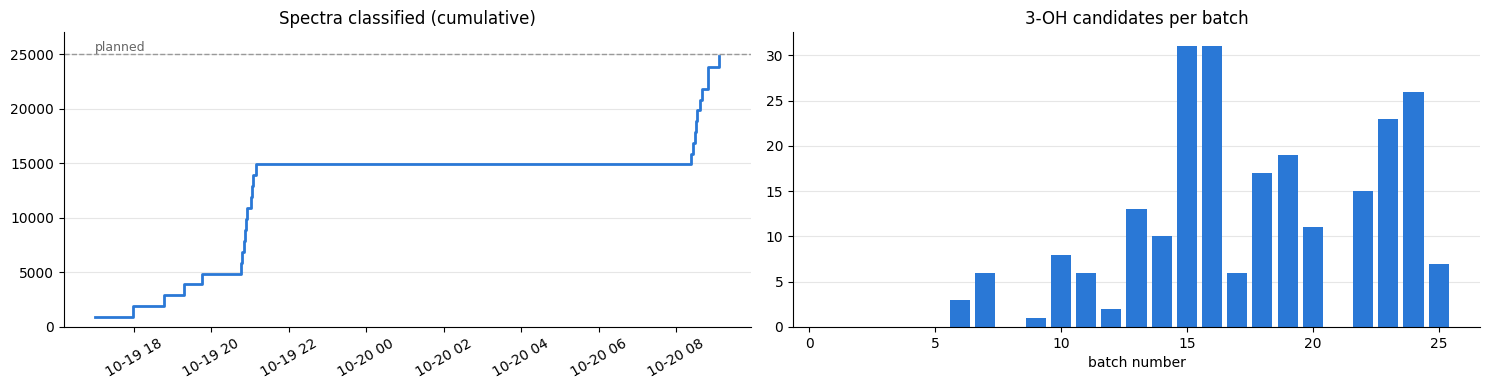

In [4]:
if n_done:
    timeline = (preds.assign(finished=pd.to_datetime(preds["classified_at"]))
                .groupby("finished").size().cumsum())
    fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(15, 4))

    ax_left.step(timeline.index, timeline.values, where="post", color=SERIES_COLOR, linewidth=2)
    ax_left.axhline(PLANNED_SPECTRA, color="0.6", linewidth=1, linestyle="--")
    ax_left.text(timeline.index[0], PLANNED_SPECTRA, "planned", color="0.4", fontsize=9, va="bottom")
    ax_left.set_title("Spectra classified (cumulative)")
    ax_left.set_ylim(0, PLANNED_SPECTRA * 1.08)
    ax_left.tick_params(axis="x", labelrotation=30)

    ax_right.bar(range(1, len(per_batch) + 1), per_batch["candidates_3oh"], width=0.8, color=SERIES_COLOR)
    ax_right.set_title("3-OH candidates per batch")
    ax_right.set_xlabel("batch number")

    for ax in (ax_left, ax_right):
        ax.grid(True, axis="y", color="0.9", linewidth=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    plt.tight_layout()
    plt.show()
else:
    print("No finished batch yet: predictions appear after the first Vertex AI job has finished.")

## Step 3: 3-OH Candidates

Newest first. `utc_approx` is computed from the SCLK, which helps to see which flyby a candidate belongs to.

For comparison, the labelled test results of notebook 15 are shown as well. The unlabelled data contains far fewer 3-OH spectra than that test set, so a larger share of the candidates will be false positives than the test precision suggests.

In [5]:
metrics_path = os.path.join(STUDY_DIR, "metrics_3oh.json")
if os.path.exists(metrics_path):
    with open(metrics_path) as f:
        study = json.load(f)
    negatives = study["fp"] + study["tn"]
    fpr = study["fp"] / negatives if negatives else float("nan")
    print(f"Notebook 15 test set: 3-OH recall {study['recall_3oh']:.1%}, precision {study['precision_3oh']:.1%}, "
          f"false-positive rate on non-3-OH {fpr:.1%} ({study['fp']} of {negatives}).\n")

candidates = preds[preds["predicted_label"] == c3.LABEL_3OH].sort_values(["classified_at", "sclk"], ascending=[False, True])
print(f"{len(candidates)} 3-OH candidates")
if len(candidates):
    with pd.option_context("display.max_colwidth", 200, "display.max_rows", 100):
        display(candidates[["sclk", "utc_approx", "event_id", "qi_ampl", "catalogue_class", "explanation"]].head(100))

    print("\nCandidates per day (UTC, approximate):")
    per_day = (candidates.assign(day=candidates["utc_approx"].dt.strftime("%Y-%m-%d"))
               .groupby("day").size().rename("candidates").to_frame())
    per_day["classified that day"] = (preds.assign(day=preds["utc_approx"].dt.strftime("%Y-%m-%d"))
                                      .groupby("day").size().reindex(per_day.index))
    display(per_day)

if preds["catalogue_class"].notna().any():
    print("\nCatalogued spectra among the classified ones (catalogue class vs. predicted label):")
    catalogued = preds[preds["catalogue_class"].notna()]
    display(pd.crosstab(catalogued["catalogue_class"], catalogued["predicted_label"]))

Notebook 15 test set: 3-OH recall 61.4%, precision 30.0%, false-positive rate on non-3-OH 10.3% (63 of 614).

235 3-OH candidates


,sclk,utc_approx,event_id,qi_ampl,catalogue_class,explanation
24360,1506224742,2005-09-24 03:17:16.053978443,19542,1.107010e-14,3,"The spectrum displays a dominant Na+ peak at 1.23 µs, followed 1.47 µs later by a prominent Na(NaOH)+ cluster peak at 2.70 µs and a secondary Na(NaOH)2+ peak at 3.74 µs (2.51 µs after Na+)."
24652,1506225713,2005-09-24 03:33:27.047537088,20513,4.150840e-14,3,"The dominant Na+ peak at ~1.86 µs is followed by a Na(NaOH)+ cluster peak at ~3.33 µs (distance of ~1.47 µs) and a Na(NaOH)2+ peak at ~4.38 µs (distance of ~2.52 µs), satisfying the core rules for..."
24157,1506225742,2005-09-24 03:33:56.047344685,20542,2.095060e-14,3,"The spectrum displays a dominant Na+ peak at 1.85 µs, followed by the diagnostic Na(NaOH)+ peak at 3.32 µs (1.47 µs later) and a prominent Na(NaOH)2+ peak at 4.38 µs (2.53 µs later)."
24774,1506226022,2005-09-24 03:38:36.045487165,20822,1.226860e-14,3,"The spectrum displays a dominant Na+ peak at 1.64 µs followed exactly 1.49 µs later by a prominent Na(NaOH)+ peak at 3.13 µs, with subsequent peaks at 3.66 µs and 4.19 µs confirming the sodium hyd..."
24826,1506226096,2005-09-24 03:39:50.044996262,20896,1.853720e-14,3,"The spectrum displays a dominant Na+ peak at 1.53 µs and a prominent Na(NaOH)+ cluster peak 1.48 µs later at 3.01 µs, conforming to the characteristic sodium hydroxide series."
24545,1506226222,2005-09-24 03:41:56.044160366,21022,4.109800e-14,3,"The spectrum displays a dominant Na+ peak at ~1.90 µs, followed by the diagnostic Na(NaOH)+ peak at ~3.35 µs (distance of ~1.45 µs) and a subsequent hydrated cluster peak Na(NaOH)(H2O)+ at ~3.87 µs."
24261,1506226262,2005-09-24 03:42:36.043895006,21062,1.463220e-14,3,"The highest peak is Na+ at ~1.47 µs, followed ~1.47 µs later by a prominent Na(NaOH)+ cluster peak at ~2.94 µs."
23715,1504620034,2005-09-05 13:32:18.699503899,10629,6.902040e-14,NaN,"The spectrum displays a dominant Na+ peak at ~1.90 µs and the diagnostic Na(NaOH)+ cluster peak ~1.46 µs later at ~3.36 µs, satisfying the core classification rules."
23300,1504624409,2005-09-05 14:45:13.670480490,12890,2.829370e-14,NaN,"The highest peak is Na+ at ~1.98 µs, followed exactly 1.49 µs later by the Na(NaOH)+ cluster peak at ~3.47 µs and a secondary Na(NaOH)2+ peak at ~4.50 µs (~2.52 µs after Na+)."
23522,1504624526,2005-09-05 14:47:10.669704199,12961,1.076800e-14,NaN,"The spectrum displays a dominant Na+ peak at 1.78 µs, followed 1.49 µs later by a well-defined Na(NaOH)+ cluster peak at 3.27 µs, with a minor Na(NaOH)2+ peak visible at 4.32 µs."



Candidates per day (UTC, approximate):


,candidates,classified that day
day,,
2005-01-16,2,212
2005-02-15,1,87
2005-02-17,3,294
2005-02-18,1,136
2005-03-08,2,264
2005-03-09,15,4088
2005-03-11,1,28
2005-05-21,11,1165
2005-05-22,5,353



Catalogued spectra among the classified ones (catalogue class vs. predicted label):


predicted_label,3-OH,non-3-OH
catalogue_class,,
3,36,36
3-P,2,0
HMOC,0,26
Stream,0,51
Test pulses,0,2


## Step 4: Candidate Plots

These are the images Gemini received, saved by notebook 16 for every 3-OH candidate.

Newest 12 candidates:


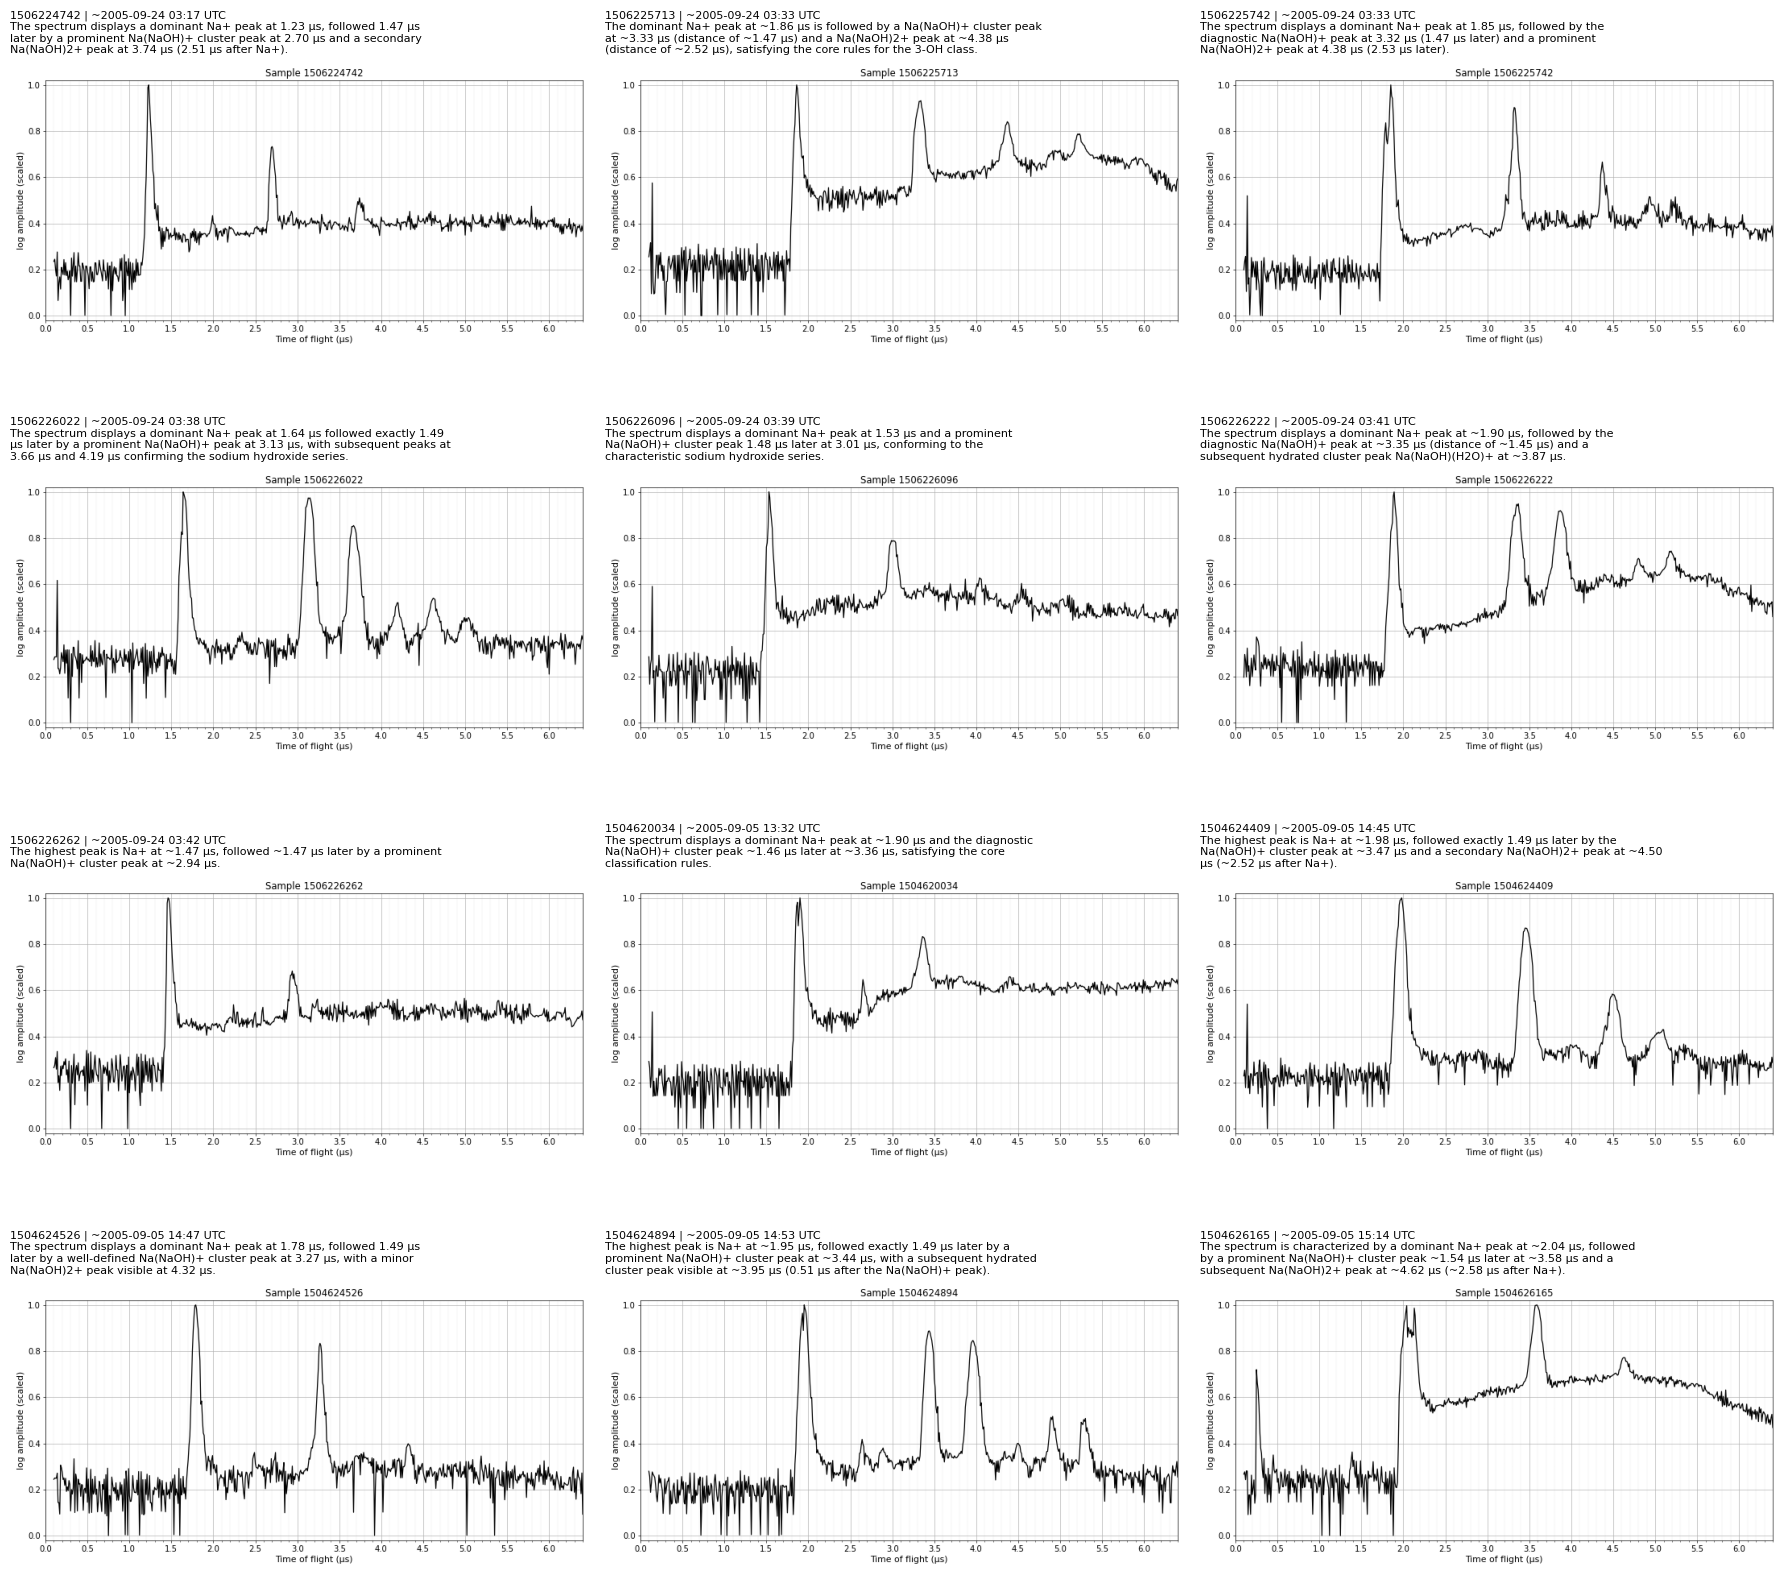

In [6]:
def show_candidate_plots(sclks):
    found = [s for s in sclks if os.path.exists(os.path.join(plots_dir, f"{s}.png"))]
    missing = [s for s in sclks if s not in found]
    if missing:
        print(f"No plot for {len(missing)} SCLK(s) (plots exist only for 3-OH candidates): {missing[:10]}")
    if not found:
        return
    info = candidates.set_index("sclk")
    n_rows = int(np.ceil(len(found) / 3))
    fig, axes = plt.subplots(n_rows, 3, figsize=(18, 4.2 * n_rows), squeeze=False)
    for ax, sclk in zip(axes.flat, found):
        ax.imshow(plt.imread(os.path.join(plots_dir, f"{sclk}.png")))
        ax.axis("off")
        if sclk in info.index:
            row = info.loc[sclk]
            caption = f"{sclk} | ~{row['utc_approx']:%Y-%m-%d %H:%M} UTC\n" + textwrap.fill(
                textwrap.shorten(str(row["explanation"]), 220), 75)
        else:
            caption = str(sclk)
        ax.set_title(caption, fontsize=8, loc="left")
    for ax in list(axes.flat)[len(found):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


if len(candidates):
    print(f"Newest {min(N_PLOTS, len(candidates))} candidates:")
    show_candidate_plots(list(candidates["sclk"].head(N_PLOTS)))
if SHOW_SCLKS:
    print("Selected SCLKs:")
    show_candidate_plots([int(s) for s in SHOW_SCLKS])

## Step 5: Vertex AI Batch Jobs (Read-Only)

Lists the `cda-3oh-*` batch jobs in the project and their state, including the job that is currently running. This only reads job information; it starts or changes nothing. Set `CHECK_VERTEX_JOBS = False` to skip it.

In [7]:
def list_3oh_jobs(project_id):
    token = subprocess.run(["gcloud", "auth", "application-default", "print-access-token"],
                           capture_output=True, text=True, check=True).stdout.strip()
    query = urllib.parse.urlencode({"pageSize": 100, "filter": 'display_name:"cda-3oh-*"'})
    url = f"https://aiplatform.googleapis.com/v1/projects/{project_id}/locations/global/batchPredictionJobs?{query}"
    result = subprocess.run(["curl", "-s", url, "-H", f"Authorization: Bearer {token}"], capture_output=True, text=True)
    data = json.loads(result.stdout or "{}")
    if "error" in data:
        raise RuntimeError(data["error"].get("message", data["error"]))
    return data.get("batchPredictionJobs", [])


if CHECK_VERTEX_JOBS:
    project_id = Config().agent_settings.project_id
    try:
        jobs = list_3oh_jobs(project_id)
    except Exception as e:
        jobs = None
        print(f"Could not query Vertex AI: {e}")
    if jobs is not None:
        rows = []
        for job in jobs:
            stats = job.get("completionStats", {})
            rows.append({
                "display name": job.get("displayName"),
                "state": job.get("state", "").replace("JOB_STATE_", ""),
                "created (UTC)": job.get("createTime", "")[:19].replace("T", " "),
                "ended (UTC)": job.get("endTime", "")[:19].replace("T", " "),
                "succeeded": stats.get("successfulCount"),
                "failed": stats.get("failedCount"),
                "job id": job.get("name", "").split("/")[-1],
            })
        job_table = pd.DataFrame(rows)
        if job_table.empty:
            print(f"No cda-3oh batch jobs found in project {project_id}.")
        else:
            display(job_table.sort_values("created (UTC)", ascending=False).reset_index(drop=True))
        print(f"Console: https://console.cloud.google.com/vertex-ai/batch-predictions?project={project_id}")

,display name,state,created (UTC),ended (UTC),succeeded,failed,job id
0,cda-3oh-inf-20261020-072432-b10,SUCCEEDED,2026-10-20 08:13:46,2026-10-20 09:04:21,999,1,2601363834652327936
1,cda-3oh-inf-20261020-072432-b09,SUCCEEDED,2026-10-20 08:09:11,2026-10-20 08:34:57,1000,NaN,8361467758059192320
2,cda-3oh-inf-20261020-072432-b08,SUCCEEDED,2026-10-20 08:02:20,2026-10-20 08:44:39,999,1,3999731518950866944
3,cda-3oh-inf-20261020-072432-b07,SUCCEEDED,2026-10-20 07:57:53,2026-10-20 08:26:55,999,1,2445145222577913856
4,cda-3oh-inf-20261020-072432-b06,SUCCEEDED,2026-10-20 07:53:20,2026-10-20 08:44:43,998,2,1269705719834214400
5,cda-3oh-inf-20261020-072432-b05,SUCCEEDED,2026-10-20 07:48:34,2026-10-20 08:28:16,998,2,6554679882553491456
6,cda-3oh-inf-20261020-072432-b04,SUCCEEDED,2026-10-20 07:43:58,2026-10-20 08:35:39,995,5,8662364508162883584
7,cda-3oh-inf-20261020-072432-b03,SUCCEEDED,2026-10-20 07:39:21,2026-10-20 08:24:16,1000,NaN,3046375772831875072
8,cda-3oh-inf-20261020-072432-b02,SUCCEEDED,2026-10-20 07:33:45,2026-10-20 08:26:48,986,14,5015574709899624448
9,cda-3oh-inf-20261020-072432-b01,SUCCEEDED,2026-10-20 07:29:10,2026-10-20 08:20:16,964,36,6443215791776071680


Console: https://console.cloud.google.com/vertex-ai/batch-predictions?project=turan-genai-bb
